<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/homeworks/base/HW1_Regression_with_inference_base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
!pip install -q ydata-profiling "numpy<2.4"  # numba в Colab пока не поддерживает NumPy 2.4

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Во многих шагах есть случайность, например в `sample`, в разбиении на фолды, в инициализации весов. Если сид не зафиксировать, при каждом запуске числа будут немного другими, и проверяющий увидит не те результаты, про которые написаны выводы. С фиксированным сидом ноутбук воспроизводится один в один, а разницу между экспериментами можно объяснять изменениями в модели, а не везением.

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [4]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [ ] Отобразите 30 случайных строк тренировочного датасета.
- [ ] Отобразите первые 5 и последние 5 объектов тестового датасета
- [ ] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [ ] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [ ] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [ ] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [ ] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [5]:
df_train.sample(30, random_state=42)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
6565,Renault KWID Climber 1.0 MT BSIV,2019,300000,35000,Petrol,Individual,Manual,First Owner,23.01 kmpl,999 CC,67 bhp,91Nm@ 4250rpm,5.0
2943,Maruti Wagon R LXI,2013,225000,58343,Petrol,Trustmark Dealer,Manual,First Owner,21.79 kmpl,998 CC,67.05 bhp,90Nm@ 3500rpm,5.0
2024,Hyundai i20 Asta 1.2,2013,360000,30000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
263,Hyundai i20 1.2 Asta,2010,300000,70000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1197 CC,80 bhp,"11.4 kgm at 4,000 rpm",5.0
4586,Skoda Octavia L and K 1.9 TDI MT,2005,250000,120000,Diesel,Individual,Manual,Third Owner,16.4 kmpl,1896 CC,90 bhp,"21.4@ 1,900(kgm@ rpm)",5.0
4479,Maruti Ciaz ZXi,2016,700000,20000,Petrol,Individual,Manual,First Owner,20.73 kmpl,1373 CC,91.1 bhp,130Nm@ 4000rpm,5.0
4881,Hyundai Grand i10 1.2 Kappa Magna BSIV,2017,445000,27000,Petrol,Individual,Manual,First Owner,18.9 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
3583,Ford Ecosport 1.5 DV5 MT Trend,2016,515000,68609,Diesel,Dealer,Manual,First Owner,22.7 kmpl,1498 CC,89.84 bhp,204Nm@ 2000-2750rpm,5.0
6361,Hyundai Verna 1.4 VTVT,2014,500000,33400,Petrol,Individual,Manual,First Owner,17.43 kmpl,1396 CC,105.5 bhp,135.3Nm@ 5000rpm,5.0
4108,Hyundai i20 Era 1.2,2015,490000,45900,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0


In [6]:
display(df_test.head())
display(df_test.tail())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Mahindra Xylo E4 BS IV,2010,229999,168000,Diesel,Individual,Manual,First Owner,14.0 kmpl,2498 CC,112 bhp,260 Nm at 1800-2200 rpm,7.0
1,Tata Nexon 1.5 Revotorq XE,2017,665000,25000,Diesel,Individual,Manual,First Owner,21.5 kmpl,1497 CC,108.5 bhp,260Nm@ 1500-2750rpm,5.0
2,Honda Civic 1.8 S AT,2007,175000,218463,Petrol,Individual,Automatic,First Owner,12.9 kmpl,1799 CC,130 bhp,172Nm@ 4300rpm,5.0
3,Honda City i DTEC VX,2015,635000,173000,Diesel,Individual,Manual,First Owner,25.1 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0
4,Tata Indica Vista Aura 1.2 Safire BSIV,2011,130000,70000,Petrol,Individual,Manual,Second Owner,16.5 kmpl,1172 CC,65 bhp,96 Nm at 3000 rpm,5.0


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
995,Hyundai i10 Magna 1.1L,2008,250000,100000,Petrol,Individual,Manual,Second Owner,19.81 kmpl,1086 CC,68.05 bhp,99.04Nm@ 4500rpm,5.0
996,Hyundai i20 2015-2017 Sportz 1.2,2017,440000,50000,Petrol,Individual,Manual,Second Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
997,Hyundai i20 Era Diesel,2009,340000,40000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
998,Hyundai i10 Asta,2012,350000,25000,Petrol,Individual,Manual,First Owner,20.36 kmpl,1197 CC,78.9 bhp,111.8Nm@ 4000rpm,5.0
999,Honda City i DTec SV,2016,700000,110000,Diesel,Individual,Manual,First Owner,26.0 kmpl,1498 CC,98.6 bhp,200Nm@ 1750rpm,5.0


In [7]:
# считаем пропуски в каждом столбце и показываем только те столбцы, где они есть
na_train = df_train.isna().sum()
na_test = df_test.isna().sum()

na_table = pd.DataFrame({'train': na_train, 'test': na_test})
na_table[na_table['train'] > 0]

,train,test
mileage,202,19
engine,202,19
max_power,196,19
torque,203,19
seats,202,19


In [8]:
cols_with_na = na_train[na_train > 0].index.tolist()
print('Столбцы с пропусками', cols_with_na)

Столбцы с пропусками ['mileage', 'engine', 'max_power', 'torque', 'seats']


In [9]:
# duplicated помечает строку как дубликат, если точно такая же уже встречалась выше
print('Полных дубликатов в train', df_train.duplicated().sum())
print('Полных дубликатов в test ', df_test.duplicated().sum())

Полных дубликатов в train 985
Полных дубликатов в test  62


**Что можно понять по случайным, первым и последним строкам.** Видно, как устроена таблица, какие в ней столбцы и в каком виде записаны значения. Здесь сразу заметно, что `mileage`, `engine` и `max_power` хранятся строками вместе с единицами измерения, `torque` записан в нескольких разных форматах, а `seats` почему-то дробный. Случайные строки полезнее первых и последних, потому что файл может быть отсортирован, и тогда начало и конец покажут только один край данных.

**Чего по ним понять нельзя.** Тридцать строк из семи тысяч ничего не говорят о распределениях, доле пропусков, редких категориях, выбросах и дубликатах. Для этого нужны `describe`, `isna`, `duplicated` и графики.

**Достаточно ли `duplicated`.** Нет. Метод находит только строки, которые совпадают полностью (в train их 985). Он не увидит одну и ту же машину, записанную с разной ценой, а такие случаи здесь есть, они разобраны в задании 2. Ещё он пропустит дубли с разным написанием (лишний пробел, другой регистр в названии) и ничего не скажет о том, пересекаются ли train и test.

In [10]:
# отчёт получается тяжёлым, поэтому сохраняем его отдельным html-файлом рядом с ноутбуком
profile = ProfileReport(df_train, title='Cars train', progress_bar=False)
profile.to_file('cars_train_profile.html')

  0%|          | 0/13 [00:00<?, ?it/s]

 46%|████▌     | 6/13 [00:00<00:00, 53.39it/s]

 92%|█████████▏| 12/13 [00:00<00:00, 39.68it/s]

100%|██████████| 13/13 [00:00<00:00, 43.26it/s]

In [11]:
# ydata-profiling при работе переключает matplotlib в режим без вывода на экран,
# эта команда возвращает графики обратно в ноутбук
%matplotlib inline

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [ ] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [ ] Отобразите такие объекты (0.15 балла)
- [ ] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [ ]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [12]:
# все столбцы, кроме цены
feature_cols = df_train.columns.drop('selling_price').tolist()

n_dups = df_train.duplicated(subset=feature_cols).sum()
print('Строк, которые повторяют более раннюю строку по признакам', n_dups)

Строк, которые повторяют более раннюю строку по признакам 1159


In [13]:
# keep=False помечает все копии сразу, а не только вторую и следующие,
# после сортировки одинаковые машины встают рядом и их удобно сравнивать глазами
dups = df_train[df_train.duplicated(subset=feature_cols, keep=False)]
print('Всего строк, у которых есть двойник', len(dups))
dups.sort_values(['name', 'year', 'km_driven', 'selling_price']).head(20)

Всего строк, у которых есть двойник 1799


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.0
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.0
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
1337,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
1595,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
2787,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
4485,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0
6640,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.0


In [14]:
# у скольких групп одинаковых машин цена при этом разная
prices_in_group = dups.groupby(feature_cols, dropna=False)['selling_price'].nunique()
print('Групп одинаковых машин', len(prices_in_group))
print('Из них с разной ценой', (prices_in_group > 1).sum())

Групп одинаковых машин 640
Из них с разной ценой 164


In [15]:
# оставляем первую строку по каждой машине и перенумеровываем строки с нуля
df_train = df_train.drop_duplicates(subset=feature_cols, keep='first').reset_index(drop=True)
df_train.shape

(5840, 13)

In [16]:
# заодно смотрим, сколько тестовых машин уже есть в train с теми же признаками
# indicator добавляет столбец _merge, где both значит что пара нашлась
train_cars = df_train[feature_cols].drop_duplicates()
merged = df_test.merge(train_cars, on=feature_cols, how='left', indicator=True)
n_seen = (merged['_merge'] == 'both').sum()
print(f'Тестовых машин с двойником в train {n_seen} из {len(df_test)}')

Тестовых машин с двойником в train 213 из 1000


По признакам без цены повторяются 1159 строк, это больше, чем 985 полных дубликатов. Разница приходится на машины с одинаковым описанием, но разной ценой, таких групп 164 из 640. После удаления в train осталось 5840 строк.

Отдельное наблюдение. У 213 тестовых машин из 1000 есть двойник в train по всем признакам. В задании не было сказано это исправлять, поэтому я не удалял, хотя вообще при чтении метрик это стоит помнить, потому что качество на тесте из-за этого выглядит немного лучше, чем было бы на совсем новых машинах.

In [17]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [ ] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [ ] Приведите тип данных к ``float``.
* [ ] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [18]:
df_train[['mileage', 'engine', 'max_power', 'torque']].head(3)

,mileage,engine,max_power,torque
0,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm
1,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm
2,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm


In [19]:
# значение выглядит как '23.4 kmpl', поэтому режем строку по пробелу и берём первую часть
# errors='coerce' превращает в NaN всё, что не похоже на число
# (в train есть строка, где в max_power записано просто ' bhp')
for df in (df_train, df_test):
    for col in ['mileage', 'engine', 'max_power']:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce').astype(float)

df_train = df_train.drop(columns='torque')
df_test = df_test.drop(columns='torque')

df_train.dtypes

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
seats            float64
dtype: object

В `mileage` смешаны две единицы измерения. У бензиновых и дизельных машин это kmpl, а у газовых km/kg. По условию мы просто убираем единицы, поэтому для газовых машин значение не совсем сопоставимо с остальными. Это упрощение, на результат оно почти не влияет, таких машин чуть больше 1%.

### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [ ] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [20]:
# нулевой расход и нулевая мощность у машины невозможны, это тоже пропуски, просто записанные нулём
for name, df in [('train', df_train), ('test', df_test)]:
    print(name, 'нулей в mileage', (df['mileage'] == 0).sum(), 'нулей в max_power', (df['max_power'] == 0).sum())
    df[['mileage', 'max_power']] = df[['mileage', 'max_power']].replace(0, np.nan)

train нулей в mileage 14 нулей в max_power 3
test нулей в mileage 1 нулей в max_power 0


In [21]:
# запоминаем статистики до заполнения, в задании 5 сравним их с тем, что получится после
stats_before = df_train.describe()

In [22]:
num_cols_with_na = ['mileage', 'engine', 'max_power', 'seats']

# медианы считаем только по train и ими же заполняем test
medians = df_train[num_cols_with_na].median()
print(medians)

df_train[num_cols_with_na] = df_train[num_cols_with_na].fillna(medians)
df_test[num_cols_with_na] = df_test[num_cols_with_na].fillna(medians)

mileage        19.40
engine       1248.00
max_power      81.86
seats           5.00
dtype: float64


In [23]:
print('Пропусков в train', df_train.isna().sum().sum())
print('Пропусков в test ', df_test.isna().sum().sum())

Пропусков в train 0
Пропусков в test  0


**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [ ] Осуществите приведение столбцов к необходимому типу.

In [24]:
for df in (df_train, df_test):
    df[['engine', 'seats']] = df[['engine', 'seats']].astype(int)

df_train.dtypes

name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine             int64
max_power        float64
seats              int64
dtype: object

### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [ ] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [ ] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [ ] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [25]:
df_train.describe().round(2)

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,5840.00,5840.00,5840.00,5840.00,5840.00,5840.00,5840.00
mean,2013.43,522960.09,73952.24,19.48,1429.45,87.95,5.43
std,4.10,535432.00,60071.14,3.87,485.66,31.58,0.98
min,1983.00,29999.00,1.00,9.00,624.00,32.80,2.00
25%,2011.00,250000.00,39000.00,17.00,1197.00,68.00,5.00
50%,2014.00,405000.00,70000.00,19.40,1248.00,81.86,5.00
75%,2017.00,640000.00,100000.00,22.30,1498.00,99.00,5.00
max,2020.00,10000000.00,2360457.00,42.00,3604.00,400.00,14.00


In [26]:
df_test.describe().round(2)

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,2013.68,617901.04,71393.34,19.36,1454.88,90.84,5.40
std,4.01,758553.86,48486.22,3.90,522.00,34.89,0.91
min,1995.00,31000.00,1303.00,9.50,624.00,34.20,4.00
25%,2011.00,250000.00,37000.00,16.55,1197.00,69.00,5.00
50%,2014.00,434999.00,61500.00,19.40,1248.00,82.42,5.00
75%,2017.00,670000.00,100000.00,22.30,1582.00,102.00,5.00
max,2020.00,6000000.00,375000.00,32.26,3604.00,280.00,9.00


In [27]:
df_train.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840,5840
unique,1924,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,91,3177,5223,5336,3603


In [28]:
df_test.describe(include='object')

,name,fuel,seller_type,transmission,owner
count,1000,1000,1000,1000,1000
unique,621,4,3,2,5
top,Maruti Alto 800 LXI,Diesel,Individual,Manual,First Owner
freq,15,534,837,877,623


In [29]:
# что изменилось в train после заполнения пропусков
stats_after = df_train.describe()
(stats_after - stats_before).loc[['mean', 'std', '50%'], num_cols_with_na].round(3)

,mileage,engine,max_power,seats
mean,-0.003,-5.969,-0.201,-0.014
std,-0.068,-6.790,-0.498,-0.013
50%,0.000,0.000,0.000,0.000


**Числовые признаки.** Цена сильно скошена вправо. В train средняя 523 тыс. при медиане 405 тыс., а максимум 10 млн. В признаках есть явные выбросы, пробег доходит до 2.36 млн км при медиане 70 тыс., встречается машина на 14 мест и мощность 400 л.с. Масштабы признаков отличаются на порядки (год около 2000, пробег в десятках тысяч, расход около 20), поэтому перед сравнением весов модели признаки нужно стандартизировать.

**Train и test.** По медианам и квартилям выборки очень похожи, год, расход, объём и мощность почти совпадают. Отличаются хвосты. В test нет экстремальных пробегов (максимум 375 тыс. км) и самых дорогих машин (максимум 6 млн), зато средняя цена выше, 618 тыс. против 523 тыс.

**Категориальные признаки.** Набор категорий в train и test одинаковый, самые частые значения тоже совпадают. Чаще всего это дизель (54% в train), частный продавец (89%), механика (91%) и первый владелец (62%). Категории сильно несбалансированы, автоматов и дилеров мало. В `name` 1924 уникальных значения на 5840 строк, кодировать такой признак напрямую бессмысленно.

**Заполнение пропусков.** Медианы после заполнения не изменились, средние сдвинулись на доли процента, стандартное отклонение стало чуть меньше (это ожидаемо, мы добавили около 200 одинаковых значений в центр). Заметного сдвига в распределения мы не внесли.

In [30]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [ ] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [ ] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [ ] Постройте pairplot по тестовым данным
- [ ] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']


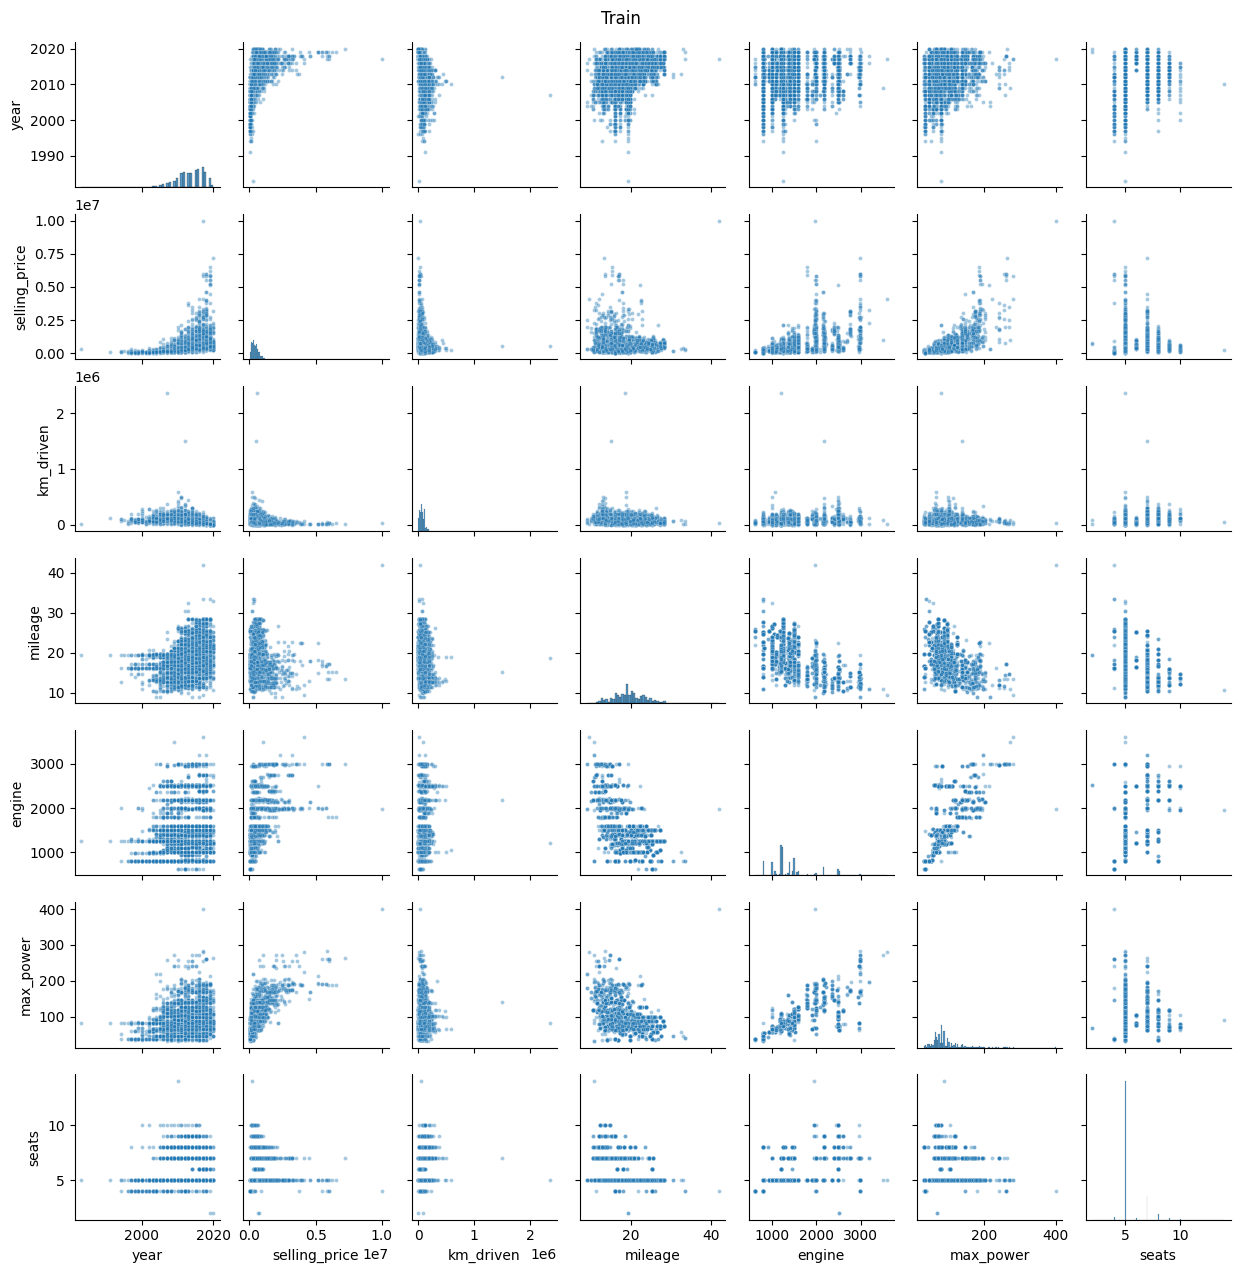

In [31]:
num_cols = df_train.select_dtypes('number').columns.tolist()
print(num_cols)

sns.pairplot(df_train[num_cols], height=1.8, plot_kws={'s': 8, 'alpha': 0.4})
plt.suptitle('Train', y=1.01)
plt.show()

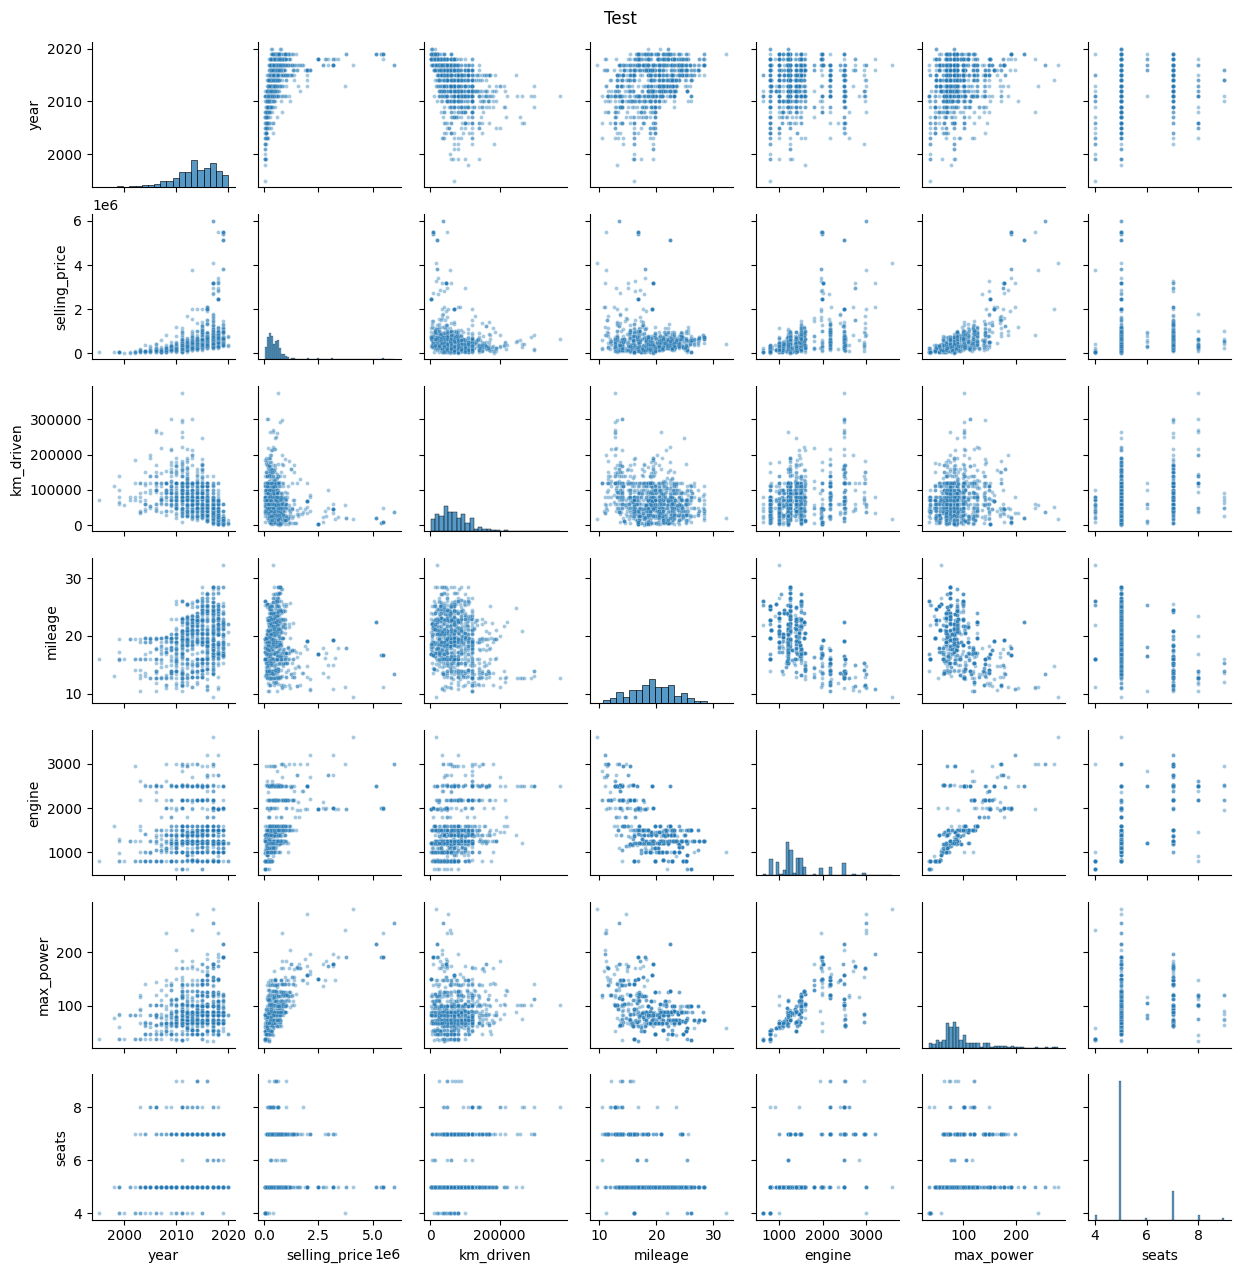

In [32]:
sns.pairplot(df_test[num_cols], height=1.8, plot_kws={'s': 8, 'alpha': 0.4})
plt.suptitle('Test', y=1.01)
plt.show()

**Связь признаков с ценой.** Она видна. Цена растёт с мощностью `max_power` и с годом выпуска, слабее с объёмом двигателя `engine`. С пробегом `km_driven` цена падает, все дорогие машины имеют небольшой пробег. Для `mileage` связь слабая и скорее отрицательная, для `seats` её почти не видно. При этом зависимости не похожи на прямые. По году и мощности облако загибается вверх, а разброс цены растёт вместе с самой ценой, так что линейной модели будет непросто.

**Гипотезы о корреляциях между признаками.** Объём двигателя и мощность растут вместе, это самая заметная пара. Расход `mileage` уменьшается с ростом объёма и мощности, значит корреляция должна быть отрицательной. Чем новее машина, тем меньше у неё пробег. У машин с большим числом мест двигатель обычно крупнее.

**Похожи ли train и test.** В целом да. Формы облаков и гистограмм совпадают, диапазоны основных признаков тоже. Разница в хвостах. В train есть несколько экстремальных объектов (пробег 1.5 и 2.4 млн км, цена 10 млн, мощность 400 л.с., 14 мест, машина 1983 года), которых нет в test. Из-за них оси на графиках train растянуты, и картинки кажутся более разными, чем есть на самом деле.

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [ ] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [ ] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

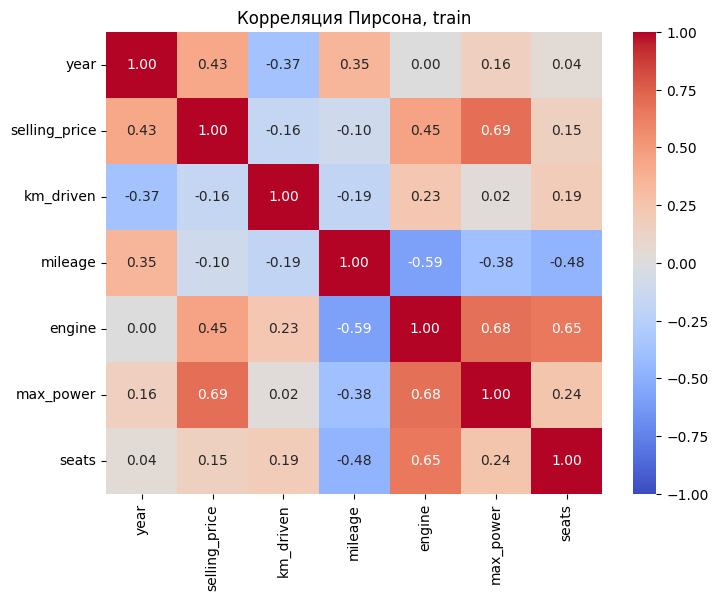

In [33]:
corr = df_train[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляция Пирсона, train')
plt.show()

In [34]:
# чтобы не искать пары глазами, разворачиваем матрицу в список пар и сортируем по модулю корреляции
# np.triu оставляет только половину матрицы над диагональю, иначе каждая пара встретится дважды
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(key=abs)

print('Самые слабые связи')
print(pairs.head(3).round(3))
print()
print('Самые сильные связи')
print(pairs.tail(5).round(3))

Самые слабые связи
year       engine       0.003
km_driven  max_power    0.025
year       seats        0.041
dtype: float64

Самые сильные связи
mileage        seats       -0.475
               engine      -0.586
engine         seats        0.652
               max_power    0.682
selling_price  max_power    0.694
dtype: float64


In [35]:
print('Корреляция года и пробега', round(corr.loc['year', 'km_driven'], 3))

Корреляция года и пробега -0.369


- [ ] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

**Наименее скоррелированы** год выпуска и объём двигателя, корреляция 0.003, то есть линейной связи практически нет.

**Довольно сильная положительная связь** у цены с мощностью (0.69), у объёма двигателя с мощностью (0.68) и у объёма двигателя с числом мест (0.65).

**Про год и пробег.** Корреляция между ними −0.37. Знак подтверждает утверждение, у более старых машин пробег в среднем больше. Но связь умеренная, поэтому это верно именно как тенденция по выборке, а не как правило для каждой машины. Старая машина с маленьким пробегом в данных встречается нередко.

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [ ] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

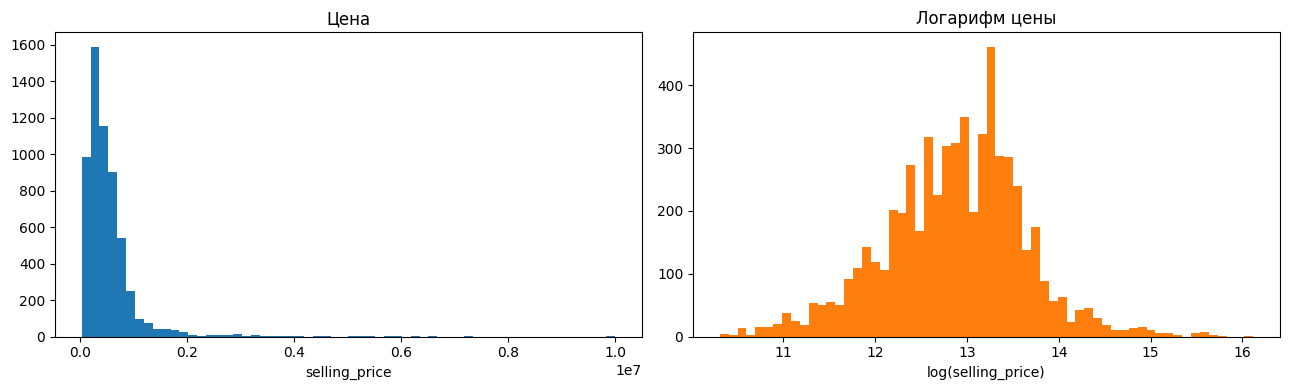

Средняя цена 522960
Медиана      405000
Скошенность  5.59


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df_train['selling_price'], bins=60)
axes[0].set_title('Цена')
axes[0].set_xlabel('selling_price')

axes[1].hist(np.log(df_train['selling_price']), bins=60, color='tab:orange')
axes[1].set_title('Логарифм цены')
axes[1].set_xlabel('log(selling_price)')

plt.tight_layout()
plt.show()

print('Средняя цена', round(df_train['selling_price'].mean()))
print('Медиана     ', round(df_train['selling_price'].median()))
print('Скошенность ', round(df_train['selling_price'].skew(), 2))

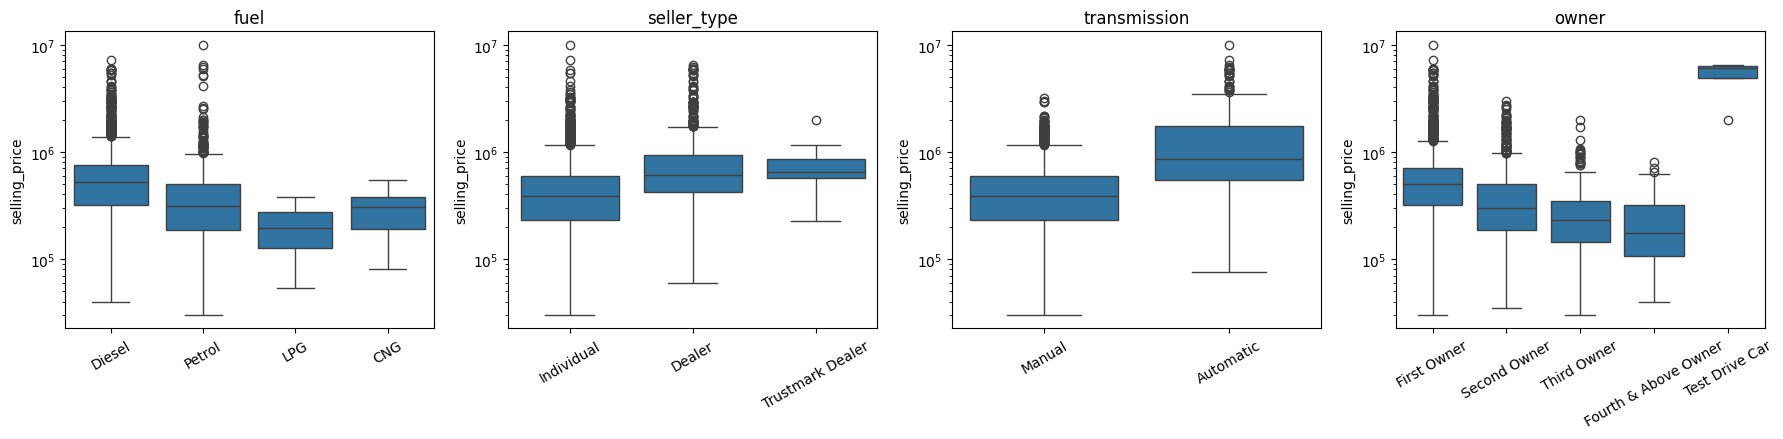

In [37]:
cat_cols = ['fuel', 'seller_type', 'transmission', 'owner']

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, cat_cols):
    sns.boxplot(data=df_train, x=col, y='selling_price', ax=ax)
    ax.set_yscale('log')  # без логарифмической шкалы дорогие машины сжимают все ящики в полоску
    ax.tick_params(axis='x', rotation=30)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [38]:
# те же различия в цифрах
for col in cat_cols:
    print(df_train.groupby(col)['selling_price'].median().sort_values().round(), end='\n\n')

fuel
LPG       195500.0
CNG       305000.0
Petrol    313000.0
Diesel    520000.0
Name: selling_price, dtype: float64

seller_type
Individual          390000.0
Dealer              610000.0
Trustmark Dealer    650000.0
Name: selling_price, dtype: float64

transmission
Manual       386500.0
Automatic    850000.0
Name: selling_price, dtype: float64

owner
Fourth & Above Owner     175000.0
Third Owner              229999.0
Second Owner             300000.0
First Owner              500000.0
Test Drive Car          6073000.0
Name: selling_price, dtype: float64



**Распределение цены.** У цены длинный правый хвост, скошенность 5.6, средняя (523 тыс.) заметно выше медианы (405 тыс.). После логарифмирования распределение становится почти симметричным. Это важно по двум причинам. Модель, которая минимизирует MSE, будет подстраиваться под редкие дорогие машины, потому что ошибка на них в абсолютном выражении самая большая. А на дешёвых машинах та же по величине ошибка превращается в огромную ошибку в процентах, и это напрямую ударит по бизнес-метрике из части 4, где считается доля прогнозов в пределах 10% от цены.

**Цена по категориям.** Категориальные признаки заметно разделяют машины по цене. Медиана у автомата 850 тыс. против 387 тыс. у механики, у дизеля 520 тыс. против 313 тыс. у бензина, у дилеров выше, чем у частников. С каждым следующим владельцем медиана падает, от 500 тыс. у первого до 175 тыс. у четвёртого. Категория Test Drive Car стоит особняком с ценой около 6 млн, но таких машин единицы. Вывод простой. В этих признаках есть информация о цене, которой нет в числовых столбцах, поэтому в части 3 их стоит добавить в модель.

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [39]:
# все числовые столбцы, кроме цены, она у нас целевая переменная
num_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

y_train = df_train['selling_price']
X_train = df_train[num_features].copy()

In [40]:
X_train.head()

,year,km_driven,mileage,engine,max_power,seats
0,2014,145500,23.40,1248,74.00,5
1,2014,120000,21.14,1498,103.52,5
2,2010,127000,23.00,1396,90.00,5
3,2007,120000,16.10,1298,88.20,5
4,2017,45000,20.14,1197,81.86,5


В модель идут шесть числовых признаков.

- `year` год выпуска
- `km_driven` пробег в километрах
- `mileage` расход топлива, сколько километров машина проезжает на литре
- `engine` объём двигателя в куб. см
- `max_power` мощность в л.с.
- `seats` число мест

Категориальные столбцы и `name` убраны, цена вынесена в `y`. Разбиение оставил как дано. Train и test уже разделены авторами задания, и причин перемешивать их заново я не вижу.

In [41]:
y_test = df_test['selling_price']
X_test = df_test[num_features].copy()

X_train.shape, X_test.shape

((5840, 6), (1000, 6))

### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [ ] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [ ] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [42]:
# сюда складываем метрики и прогнозы всех моделей, чтобы в конце сравнить их в одной таблице
results = {}
predictions = {}


def evaluate(name, model, X_tr, X_te):
    """Считает R2 и MSE на train и test, печатает их и запоминает под именем name"""
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    results[name] = {
        'R2 train': r2_score(y_train, pred_tr),
        'R2 test': r2_score(y_test, pred_te),
        'MSE train': MSE(y_train, pred_tr),
        'MSE test': MSE(y_test, pred_te),
    }
    predictions[name] = (pred_tr, pred_te)
    for metric, value in results[name].items():
        # R2 печатаем обычным числом, а MSE в формате 1.23e+11, иначе получится строка из двенадцати цифр
        print(metric.ljust(10), f'{value:.4f}' if 'R2' in metric else f'{value:.3e}')

In [43]:
lr = LinearRegression()
lr.fit(X_train, y_train)

evaluate('LinearRegression', lr, X_train, X_test)

R2 train   0.5939
R2 test    0.5945
MSE train  1.164e+11
MSE test   2.331e+11


R² на train и test почти одинаковый, 0.594 и 0.595. Переобучения нет, но и качество среднее, модель объясняет около 59% разброса цены.

MSE в исходном виде читать неудобно, поэтому смотрю на корень из него. На train модель ошибается в среднем примерно на 341 тыс., на test на 483 тыс. При медианной цене 405 тыс. это много.

MSE на test вдвое выше, чем на train, хотя R² одинаковый. Противоречия тут нет. В test разброс цен больше (стандартное отклонение 759 тыс. против 535 тыс.), а R² как раз сравнивает ошибку модели с этим разбросом.

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [ ] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [44]:
# fit считает средние и стандартные отклонения только по train,
# transform применяет их и к train, и к test
scaler = StandardScaler()
scaler.fit(X_train)

# scaler возвращает обычный массив, поэтому заворачиваем обратно в таблицу с названиями столбцов
X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=num_features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=num_features)

X_train_scaled.describe().loc[['mean', 'std']].round(2)

,year,km_driven,mileage,engine,max_power,seats
mean,0.0,-0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [45]:
lr_scaled = LinearRegression()
lr_scaled.fit(X_train_scaled, y_train)

evaluate('LinearRegression, scaled', lr_scaled, X_train_scaled, X_test_scaled)

R2 train   0.5939
R2 test    0.5945
MSE train  1.164e+11
MSE test   2.331e+11


После стандартизации метрики не изменились ни в одном знаке. Так и должно быть. Линейная регрессия без регуляризации просто пересчитывает веса под новый масштаб, а прогнозы остаются теми же.

Польза от стандартизации в другом. Теперь веса можно сравнивать между собой, а в моделях с регуляризацией штраф будет действовать на все признаки одинаково.

### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [ ] Какой признак оказался наиболее информативным в предсказании цены?

In [46]:
coefs = pd.DataFrame({
    'до стандартизации': lr.coef_,
    'после стандартизации': lr_scaled.coef_,
}, index=num_features)

# сортируем по модулю веса после стандартизации, знак при этом сохраняется
coefs.sort_values('после стандартизации', key=abs, ascending=False).round(1)

,до стандартизации,после стандартизации
max_power,10330.3,326181.4
year,36409.5,149106.9
engine,125.3,60857.9
km_driven,-0.7,-44615.0
mileage,9306.8,36018.5
seats,-19798.9,-19447.6


Самый информативный признак `max_power`. Его вес (326 тыс.) больше чем вдвое превышает вес следующего признака, года выпуска (149 тыс.). Это согласуется с корреляциями из задания 7, где мощность тоже была сильнее всего связана с ценой.

По весам до стандартизации такой вывод сделать было нельзя. Там самыми большими по модулю были веса у года и числа мест, но только из-за единиц измерения.

Ещё одна деталь. Вес `mileage` получился положительным, хотя корреляция расхода с ценой слабая отрицательная (−0.1). Это следствие связи признаков между собой, `mileage` заметно скоррелирован с `engine` и `max_power`. Поэтому знак отдельного веса здесь нужно толковать осторожно.

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [ ] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [ ] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [47]:
lasso = Lasso()
lasso.fit(X_train_scaled, y_train)

evaluate('Lasso, alpha=1', lasso, X_train_scaled, X_test_scaled)

R2 train   0.5939
R2 test    0.5945
MSE train  1.164e+11
MSE test   2.331e+11


In [48]:
print('Занулённых весов', (lasso.coef_ == 0).sum())

pd.DataFrame({'LinearRegression': lr_scaled.coef_, 'Lasso': lasso.coef_}, index=num_features).round(1)

Занулённых весов 0


,LinearRegression,Lasso
year,149106.9,149106.8
km_driven,-44615.0,-44613.8
mileage,36018.5,36016.6
engine,60857.9,60853.0
max_power,326181.4,326182.2
seats,-19447.6,-19444.8


Lasso с `alpha=1` дал те же метрики, что и обычная регрессия, и не занулил ни одного веса.

Причина в масштабе. Цены измеряются сотнями тысяч, веса при стандартизованных признаках получаются порядка десятков и сотен тысяч, и штраф с `alpha=1` на этом фоне незаметен, веса сдвинулись на единицы. Чтобы L1 начал отбирать признаки, `alpha` должен быть на несколько порядков больше.

Вторая причина в том, что признаков всего шесть и каждый несёт какую-то информацию о цене. Совсем лишних среди них нет.

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [49]:
alphas = [0.1, 1, 10, 100, 1000, 10000, 100000]

gs_lasso = GridSearchCV(Lasso(), {'alpha': alphas}, cv=10, scoring='r2')
gs_lasso.fit(X_train_scaled, y_train)

# средний R2 по 10 фолдам для каждого alpha
pd.DataFrame({
    'alpha': alphas,
    'R2 на кросс-валидации': gs_lasso.cv_results_['mean_test_score'],
}).round(4)

,alpha,R2 на кросс-валидации
0,0.1,0.5690
1,1.0,0.5690
2,10.0,0.5690
3,100.0,0.5690
4,1000.0,0.5697
5,10000.0,0.5738
6,100000.0,0.5315


In [50]:
n_fits = len(gs_lasso.cv_results_['params']) * 10
print('Обучений на фолдах', n_fits, 'и ещё одно финальное на всём train')
print('Лучший alpha', gs_lasso.best_params_['alpha'])
print('Занулённых весов', (gs_lasso.best_estimator_.coef_ == 0).sum())
print()

# best_estimator_ это модель с лучшим alpha, уже обученная заново на всём train
evaluate('Lasso, GridSearch', gs_lasso.best_estimator_, X_train_scaled, X_test_scaled)

Обучений на фолдах 70 и ещё одно финальное на всём train
Лучший alpha 10000
Занулённых весов 1

R2 train   0.5911
R2 test    0.5826
MSE train  1.172e+11
MSE test   2.399e+11


In [51]:
pd.Series(gs_lasso.best_estimator_.coef_, index=num_features).round(1)

year         149087.7
km_driven    -33048.4
mileage       15490.2
engine        20203.9
max_power    330983.6
seats            -0.0
dtype: float64

**Сколько моделей обучено.** В сетке 7 значений `alpha`, фолдов 10, получается 70 обучений. Плюс одно финальное, когда GridSearchCV заново обучает лучшую модель на всём train. Итого 71.

**Лучший коэффициент и веса.** Лучший `alpha` равен 10 000. При нём занулился один вес, у `seats`. Веса `km_driven`, `mileage` и `engine` заметно уменьшились, а у `max_power` и `year` почти не изменились.

**Что с качеством.** На кросс-валидации R² вырос совсем немного (0.574 против 0.569), а на test стал даже чуть ниже, 0.583 против 0.595. Регуляризация здесь почти ничего не даёт, потому что модель из шести признаков и так не переобучена.

**Оговорка про методику.** Признаки я стандартизировал один раз по всему train до кросс-валидации, как сказано в задании 11. Поэтому скейлер видел валидационные фолды. Строго говоря, это небольшая утечка, и правильнее было бы положить скейлер и модель в один `Pipeline`. На 5840 строках эффект пренебрежимо мал.

**Ваша задача 2:**

- [ ] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [ ] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [52]:
# l1_ratio задаёт долю L1 в штрафе, при 1 это чистый Lasso, при 0 чистый Ridge
params_en = {
    'alpha': [0.1, 1, 10, 100, 1000, 10000, 100000],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

gs_en = GridSearchCV(ElasticNet(), params_en, cv=10, scoring='r2')
gs_en.fit(X_train_scaled, y_train)

n_fits = len(gs_en.cv_results_['params']) * 10
print('Обучений на фолдах', n_fits, 'и ещё одно финальное на всём train')
print('Лучшие параметры', gs_en.best_params_)
print('R2 на кросс-валидации', round(gs_en.best_score_, 4))
print()

evaluate('ElasticNet, GridSearch', gs_en.best_estimator_, X_train_scaled, X_test_scaled)

Обучений на фолдах 350 и ещё одно финальное на всём train
Лучшие параметры {'alpha': 1, 'l1_ratio': 0.9}
R2 на кросс-валидации 0.5772

R2 train   0.5899
R2 test    0.5726
MSE train  1.176e+11
MSE test   2.457e+11


In [53]:
# та же сетка таблицей, строки это alpha, столбцы это l1_ratio
cv_en = pd.DataFrame(gs_en.cv_results_['params'])
cv_en['R2'] = gs_en.cv_results_['mean_test_score']
cv_en.pivot(index='alpha', columns='l1_ratio', values='R2').round(4)

l1_ratio,0.1,0.3,0.5,0.7,0.9
alpha,,,,,
0.1,0.5769,0.5759,0.5746,0.5728,0.5704
1.0,0.5148,0.5362,0.5565,0.5726,0.5772
10.0,0.1639,0.1995,0.2528,0.3410,0.5040
100.0,0.0104,0.0166,0.0274,0.0515,0.1502
1000.0,-0.0098,-0.0091,-0.0080,-0.0052,0.0081
10000.0,-0.0119,-0.0118,-0.0117,-0.0114,-0.0101
100000.0,-0.0121,-0.0121,-0.0121,-0.0120,-0.0120


**Сколько моделей обучено.** 7 значений `alpha` на 5 значений `l1_ratio` дают 35 комбинаций. На 10 фолдах это 350 обучений и ещё одно финальное, всего 351.

**Лучшие гиперпараметры.** `alpha=1` и `l1_ratio=0.9`, R² на кросс-валидации 0.577. Это модель, в которой штраф на 90% состоит из L1, то есть почти Lasso.

**Что видно по таблице.** При `alpha` от 10 и выше качество резко падает, а дальше R² уходит к нулю. Модель сжимает все веса и предсказывает почти константу. Чем больше в штрафе доля L2, тем раньше это происходит.

**Итог по части 2.** На test у ElasticNet R² 0.573, это ниже, чем у обычной регрессии (0.595). На шести числовых признаках ни Lasso, ни ElasticNet качество на тесте не улучшили. Различия между моделями на кросс-валидации в третьем знаке, это на уровне шума.

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [ ] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [ ] Удалите из них столбец `name`

In [54]:
print('Уникальных значений в name', df_train['name'].nunique(), 'на', len(df_train), 'строк')

Уникальных значений в name 1924 на 5840 строк


In [55]:
X_train_cat = df_train.drop(columns='selling_price')
X_test_cat = df_test.drop(columns='selling_price')

X_train_cat = X_train_cat.drop(columns='name')
X_test_cat = X_test_cat.drop(columns='name')

В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [56]:
assert X_train_cat.shape == (5840, 10)

In [57]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [ ] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [58]:
cat_features = ['fuel', 'seller_type', 'transmission', 'owner', 'seats']
real_features = ['year', 'km_driven', 'mileage', 'engine', 'max_power']

X_train_cat[cat_features].nunique()

fuel            4
seller_type     3
transmission    2
owner           5
seats           9
dtype: int64

In [59]:
# drop='first' убирает по одному столбцу у каждого признака, чтобы не было мультиколлинеарности
# sparse_output=False и set_output дают на выходе обычную таблицу с понятными названиями столбцов
# handle_unknown='ignore' нужен на будущее, если в новых данных встретится незнакомая категория,
# кодировщик не упадёт, а поставит нули во все её столбцы
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ohe.set_output(transform='pandas')

# кодировщик, как и скейлер, обучаем только на train
ohe.fit(X_train_cat[cat_features])
train_ohe = ohe.transform(X_train_cat[cat_features])
test_ohe = ohe.transform(X_test_cat[cat_features])

train_ohe.head(3)

,fuel_Diesel,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner,seats_4,seats_5,seats_6,seats_7,seats_8,seats_9,seats_10,seats_14
0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
# вещественные признаки стандартизируем заново, потому что seats теперь ушёл в категориальные
scaler_cat = StandardScaler()
scaler_cat.fit(X_train_cat[real_features])

train_real = pd.DataFrame(scaler_cat.transform(X_train_cat[real_features]), columns=real_features)
test_real = pd.DataFrame(scaler_cat.transform(X_test_cat[real_features]), columns=real_features)

# склеиваем числовую и закодированную части по столбцам
X_train_ohe = pd.concat([train_real, train_ohe], axis=1)
X_test_ohe = pd.concat([test_real, test_ohe], axis=1)

print(X_train_ohe.shape, X_test_ohe.shape)
X_train_ohe.columns.tolist()

(5840, 23) (1000, 23)


['year',
 'km_driven',
 'mileage',
 'engine',
 'max_power',
 'fuel_Diesel',
 'fuel_LPG',
 'fuel_Petrol',
 'seller_type_Individual',
 'seller_type_Trustmark Dealer',
 'transmission_Manual',
 'owner_Fourth & Above Owner',
 'owner_Second Owner',
 'owner_Test Drive Car',
 'owner_Third Owner',
 'seats_4',
 'seats_5',
 'seats_6',
 'seats_7',
 'seats_8',
 'seats_9',
 'seats_10',
 'seats_14']

После кодирования получилось 23 признака, из них 5 вещественных и 18 индикаторов. У каждого категориального признака убран первый столбец, базовыми категориями стали CNG, Dealer, Automatic, First Owner и 2 места.

`seats` закодирован как категория, а не оставлен числом. Цена зависит от числа мест не линейно, семиместная машина это другой класс автомобиля, а не пятиместная плюс два места.

### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [ ] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [ ] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [61]:
# сначала обычная регрессия на новых признаках, чтобы отделить эффект признаков от эффекта регуляризации
lr_ohe = LinearRegression()
lr_ohe.fit(X_train_ohe, y_train)

evaluate('LinearRegression, OHE', lr_ohe, X_train_ohe, X_test_ohe)

R2 train   0.6686
R2 test    0.6260
MSE train  9.499e+10
MSE test   2.150e+11


In [62]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]

gs_ridge = GridSearchCV(Ridge(), {'alpha': ridge_alphas}, cv=10, scoring='r2')
gs_ridge.fit(X_train_ohe, y_train)

pd.DataFrame({
    'alpha': ridge_alphas,
    'R2 на кросс-валидации': gs_ridge.cv_results_['mean_test_score'],
}).round(4)

,alpha,R2 на кросс-валидации
0,0.01,0.6174
1,0.10,0.6177
2,1.00,0.6201
3,10.00,0.6228
4,100.00,0.6185
5,1000.00,0.6003
6,10000.00,0.4340


In [63]:
print('Лучший alpha', gs_ridge.best_params_['alpha'])
print()

evaluate('Ridge, OHE, GridSearch', gs_ridge.best_estimator_, X_train_ohe, X_test_ohe)

Лучший alpha 10

R2 train   0.6551
R2 test    0.6455
MSE train  9.887e+10
MSE test   2.037e+11


In [64]:
# все модели рядом
results_table = pd.DataFrame(results).T

# MSE переводим в короткую запись вида 1.16e+11, иначе таблицу невозможно читать
for col in ['MSE train', 'MSE test']:
    results_table[col] = results_table[col].map('{:.3e}'.format)

results_table.round(4)

,R2 train,R2 test,MSE train,MSE test
LinearRegression,0.5939,0.5945,1.164e+11,2.331e+11
"LinearRegression, scaled",0.5939,0.5945,1.164e+11,2.331e+11
"Lasso, alpha=1",0.5939,0.5945,1.164e+11,2.331e+11
"Lasso, GridSearch",0.5911,0.5826,1.172e+11,2.399e+11
"ElasticNet, GridSearch",0.5899,0.5726,1.176e+11,2.457e+11
"LinearRegression, OHE",0.6686,0.6260,9.499e+10,2.150e+11
"Ridge, OHE, GridSearch",0.6551,0.6455,9.887e+10,2.037e+11


Да, качество выросло. У Ridge с `alpha=10` R² на test 0.646 против 0.595 у лучшей модели на вещественных признаках, MSE на test снизился с 2.33e+11 до 2.04e+11.

Основной прирост дали сами категориальные признаки. Обычная линейная регрессия на тех же 23 признаках уже показывает 0.626 на test.

Регуляризация добавила ещё около 0.02 и сократила разрыв между train и test. Без неё было 0.669 и 0.626, с ней 0.655 и 0.646. В отличие от части 2, здесь она полезна. Среди индикаторов есть очень редкие (14 мест у одной машины, 2 места у двух, Test Drive Car у четырёх), и без штрафа веса на них получаются неустойчивыми.

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [ ] Реализуйте метрику `business_metric`
- [ ] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [65]:
def business_metric(y_true, y_pred):
    """Доля прогнозов, которые отличаются от реальной цены не больше чем на 10%"""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    relative_error = np.abs(y_pred - y_true) / y_true
    # сравнение даёт массив из True и False, а среднее по нему и есть доля True
    return np.mean(relative_error <= 0.1)


# проверка на игрушечном примере, в 10% попадают два прогноза из четырёх
print(business_metric([100, 100, 100, 100], [105, 91, 111, 50]))

0.5


In [66]:
# прогнозы всех моделей мы сохраняли в predictions внутри evaluate
rows = {}
for name, (pred_tr, pred_te) in predictions.items():
    rows[name] = {
        'business train': business_metric(y_train, pred_tr),
        'business test': business_metric(y_test, pred_te),
        'R2 test': results[name]['R2 test'],
    }

pd.DataFrame(rows).T.sort_values('business test', ascending=False).round(4)

,business train,business test,R2 test
"ElasticNet, GridSearch",0.2209,0.247,0.5726
"LinearRegression, OHE",0.2135,0.246,0.6260
"Ridge, OHE, GridSearch",0.2134,0.245,0.6455
"Lasso, alpha=1",0.2175,0.232,0.5945
"LinearRegression, scaled",0.2175,0.232,0.5945
LinearRegression,0.2175,0.232,0.5945
"Lasso, GridSearch",0.2152,0.232,0.5826


In [67]:
# где именно ошибается модель с лучшим R2, смотрим долю попаданий в 10% по четвертям цены
best_pred = predictions['Ridge, OHE, GridSearch'][1]
hit = np.abs(best_pred - y_test) / y_test <= 0.1
price_group = pd.qcut(y_test, 4, labels=['дешёвые', 'ниже среднего', 'выше среднего', 'дорогие'])

print(hit.groupby(price_group, observed=True).mean().round(3))
print()
print('Отрицательных прогнозов цены на test', (best_pred < 0).sum())

selling_price
дешёвые          0.079
ниже среднего    0.212
выше среднего    0.351
дорогие          0.340
Name: selling_price, dtype: float64

Отрицательных прогнозов цены на test 62


Все модели попадают в 10% от реальной цены примерно для четверти машин, от 23.2% до 24.7% на test.

Формально лучшая ElasticNet (24.7%), за ней линейная регрессия на OHE (24.6%) и Ridge на OHE (24.5%). Но разница между ними это одна или две машины из тысячи, то есть шум. По бизнес-метрике модели практически неразличимы, хотя по R² Ridge на OHE заметно лучше остальных (0.646).

Если выбирать одну модель, я бы взял Ridge на OHE. По бизнес-метрике она на уровне лидера, а по R² и MSE лучшая.

**Почему метрика такая низкая и не растёт вместе с R².** Модели учатся уменьшать квадрат ошибки в абсолютных единицах, а бизнес-метрика считает ошибку в процентах от цены. Это разные цели. Модель подстраивается под дорогие машины, а на дешёвых промахивается сильнее всего. Среди самой дешёвой четверти машин в 10% попадает только 8% прогнозов, среди дорогой половины около 35%. Для 62 тестовых машин прогноз цены вообще получился отрицательным.

Чтобы заметно поднять именно эту метрику, нужно менять постановку задачи (например, предсказывать логарифм цены), а не подбирать коэффициент регуляризации. В рамках этого задания я этого не делал.

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

## Сохранение модели для приложения

В приложение идёт Ridge на OHE-признаках, лучшая модель по R² и MSE. В частях 3 и 4 кодирование и стандартизация делались отдельными шагами. Чтобы приложению не пришлось повторять их вручную, собираю всё в один `Pipeline`. Он принимает таблицу с обычными столбцами и сам масштабирует числа и кодирует категории.

In [68]:
import pickle

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [69]:
# ColumnTransformer применяет к каждой группе столбцов своё преобразование,
# числовые стандартизирует, категориальные кодирует так же, как в задании 16
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), real_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features),
])

best_alpha = gs_ridge.best_params_['alpha']

final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=best_alpha)),
])

# на вход идёт таблица из задания 15, без ручного кодирования и стандартизации
final_model.fit(X_train_cat, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['year','km_driven','fuel',...,'engine','max_power','seats']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concaten

In [70]:
# пайплайн должен давать те же прогнозы, что и модель из задания 17
pipe_pred = final_model.predict(X_test_cat)
print('Прогнозы совпадают', np.allclose(pipe_pred, predictions['Ridge, OHE, GridSearch'][1]))
print('R2 test', round(r2_score(y_test, pipe_pred), 4))
print('business test', business_metric(y_test, pipe_pred))

Прогнозы совпадают True
R2 test 0.6455
business test 0.245


In [71]:
# всё, что нужно приложению, кладём в один словарь
# медианы и категории переводим в обычные числа и списки Python, так файл меньше зависит от версий библиотек
artifacts = {
    'model': final_model,
    'real_features': real_features,
    'cat_features': cat_features,
    'medians': {col: float(value) for col, value in medians.items()},
    'categories': {col: sorted(X_train_cat[col].unique().tolist()) for col in cat_features},
    'metrics': {
        'R2 test': float(r2_score(y_test, pipe_pred)),
        'business test': float(business_metric(y_test, pipe_pred)),
    },
}

with open('model.pickle', 'wb') as f:  # wb значит запись в бинарном режиме
    pickle.dump(artifacts, f, protocol=pickle.HIGHEST_PROTOCOL)

In [72]:
# проверяем, что файл читается и модель из него предсказывает цену для новой машины
with open('model.pickle', 'rb') as f:
    loaded = pickle.load(f)

new_car = pd.DataFrame([{
    'year': 2016, 'km_driven': 60000, 'mileage': 20.0, 'engine': 1200, 'max_power': 85.0,
    'fuel': 'Petrol', 'seller_type': 'Individual', 'transmission': 'Manual',
    'owner': 'First Owner', 'seats': 5,
}])

print('Прогноз цены', round(loaded['model'].predict(new_car)[0]))

Прогноз цены 521815


In [73]:
# данные для приложения, очищенный train пойдёт на графики, а 20 тестовых машин без цены на проверку загрузки файла
df_train.to_csv('cars_train_clean.csv', index=False)
df_test.drop(columns='selling_price').sample(20, random_state=42).to_csv('sample_cars.csv', index=False)

В `model.pickle` лежит словарь. В нём сам пайплайн (скейлер, кодировщик и Ridge), медианы для заполнения пропусков, списки признаков, допустимые категории для выпадающих списков и метрики на тесте. Этого достаточно, чтобы приложение сделало прогноз для новой машины, не обращаясь к ноутбуку.

# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.